# CPW Microwave Drive Model for NV Centers

This notebook models a coplanar waveguide (CPW) used to drive NV centers with microwaves. It explores how geometry and distance affect: magnetic field strength (B1), required current, required microwave power, and resistive heating at cryogenic temperatures.

The physics model uses simple analytical approximations valid for near-field CPW drive conditions. The notebook includes plots of B1 vs current, required current vs Rabi frequency, power vs distance/width, RF resistance, dissipated power, and drive efficiency.

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import EngFormatter

sns.set_theme(context='notebook', style='darkgrid', palette='Set1')
sns.color_palette("Paired")
plt.rcParams.update({'font.size': 12})

In [68]:
# Physical constants
mu0 = 4 * np.pi * 1e-7  # vacuum permeability [H/m]
Z0 = 50.0  # characteristic impedance [ohm] for the transmission line
gamma_e = 28e9  # electron gyromagnetic ratio [Hz/T] for NV centers

# Resistivities
rho_RT = 1.7e-8  # room temperature copper resistivity [ohm*m]
rho_cryo = 2e-11  # conservative cryogenic copper resistivity [ohm*m]

# Frequency ranges
f_nv = 2.87e9  # main NV frequency [Hz]
f_sweep = np.linspace(2e9, 6e9, 401)  # frequency sweep [Hz]
omega_sweep = 2 * np.pi * f_sweep  # angular frequency [rad/s]

# CPW geometry
distances = np.array([50e-6, 100e-6, 200e-6, 500e-6])  # distance from CPW to NV [m]
widths = np.array([2e-3, 1e-3, 0.5e-3, 0.2e-3])  # trace widths [m]
thickness = 18e-6  # copper thickness [m]
length = 37e-3  # trace length [m]
straight_length = 19.2e-3  # length of straight section near NV [m]

# Derived helper functions
def b1_from_current(I, r):
    """Magnetic field amplitude from a straight conductor approximation."""
    return mu0 * I / (2 * np.pi * r)

def current_for_rabi(Omega, r):
    """Current required to achieve Rabi frequency Omega at distance r."""
    B1_required = Omega / gamma_e
    return 2 * np.pi * r * B1_required / mu0

def power_from_current(I):
    """Power delivered into a 50 ohm line for peak current I."""
    return I**2 * Z0   # I is RMS

def skin_depth(rho, omega):
    return np.sqrt(2 * rho / (omega * mu0))

def rf_resistance(rho, width, omega):
    """Approximate RF resistance for a trace of width w and effective skin depth delta."""
    delta = skin_depth(rho, omega)
    return rho * length / (2 *width * np.maximum(delta, 1e-12))

def dissipated_power(I, R_rf):
    return I**2 * R_rf

## 1. Magnetic field strength B1 vs current (infinitly thin and long wire)

Plot B1 as a function of current for several distances from the CPW. This shows the strong distance dependence of the near-field microwave drive.

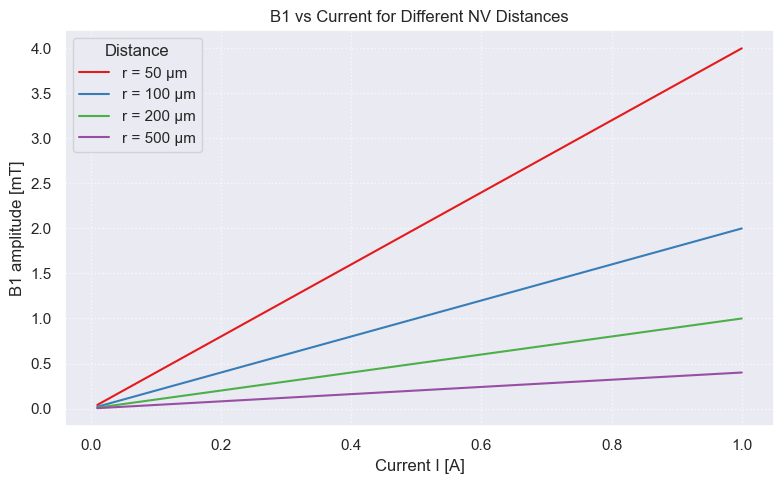

In [70]:

I_values = np.linspace(0.01, 1.0, 200)  # current range [A]
plt.figure(figsize=(8, 5))
for i, r in enumerate(distances):
    plt.plot(I_values, b1_from_current(I_values, r) * 1e3, label=f'r = {r*1e6:.0f} µm')

plt.xlabel('Current I [A]')
plt.ylabel('B1 amplitude [mT]')
plt.title('B1 vs Current for Different NV Distances')
plt.legend(title='Distance')
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

## 2. Required current vs Rabi frequency

Compute the current needed to generate Rabi frequencies between 1 and 20 MHz at each geometric distance.

10 MHz required current at r=50 µm: 0.089 A
10 MHz required current at r=100 µm: 0.179 A
10 MHz required current at r=200 µm: 0.357 A
10 MHz required current at r=500 µm: 0.893 A


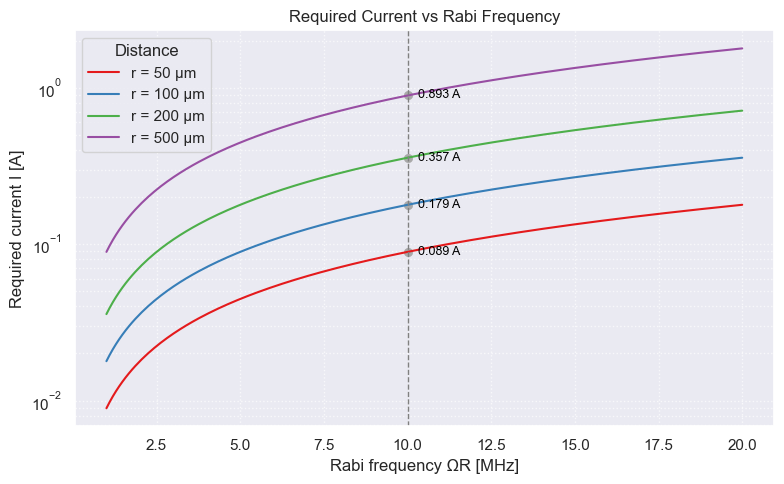

In [71]:
Omega_range = np.linspace(1e6, 20e6, 200)  # Rabi frequencies [Hz]
fixed_rabi_line = 10e6  # highlight 10 MHz

plt.figure(figsize=(8, 5))
for r in distances:
    I_req = current_for_rabi(Omega_range, r)
    plt.plot(Omega_range * 1e-6, I_req, label=f'r = {r*1e6:.0f} µm')

# Draw a vertical line at 10 MHz and label its current values
plt.axvline(fixed_rabi_line * 1e-6, color='gray', linestyle='--', linewidth=1)
for r in distances:
    I_10MHz = current_for_rabi(fixed_rabi_line, r)
    plt.scatter([fixed_rabi_line * 1e-6], [I_10MHz], color='darkgray', linewidth=0.5, zorder=1)
    plt.text(
        fixed_rabi_line * 1e-6 + 0.3,
        I_10MHz,
        f'{I_10MHz:.3f} A',
        va='center',
        fontsize=9,
        color='black'
    )
    print(f'10 MHz required current at r={r*1e6:.0f} µm: {I_10MHz:.3f} A')

plt.xlabel('Rabi frequency ΩR [MHz]')
plt.ylabel('Required current I [A]')
plt.title('Required Current vs Rabi Frequency')
plt.legend(title='Distance')
plt.yscale('log')
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

## 3. Required power vs distance for fixed Rabi frequency

Use a fixed 5 MHz Rabi frequency and plot the power needed into a 50 ohm line as a function of distance.

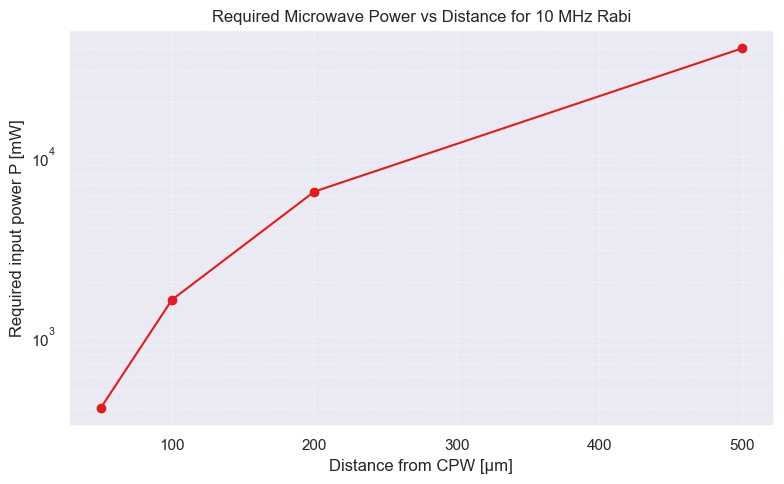

In [72]:
fixed_rabi = 10e6  # target Rabi frequency [Hz]
I_fixed = current_for_rabi(fixed_rabi, distances)
P_fixed = power_from_current(I_fixed)

plt.figure(figsize=(8, 5))
plt.plot(distances * 1e6, P_fixed * 1e3, marker='o')
plt.xlabel('Distance from CPW [µm]')
plt.ylabel('Required input power P [mW]')
plt.title(f'Required Microwave Power vs Distance for {fixed_rabi * 1e-6:.0f} MHz Rabi')
plt.yscale('log')
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

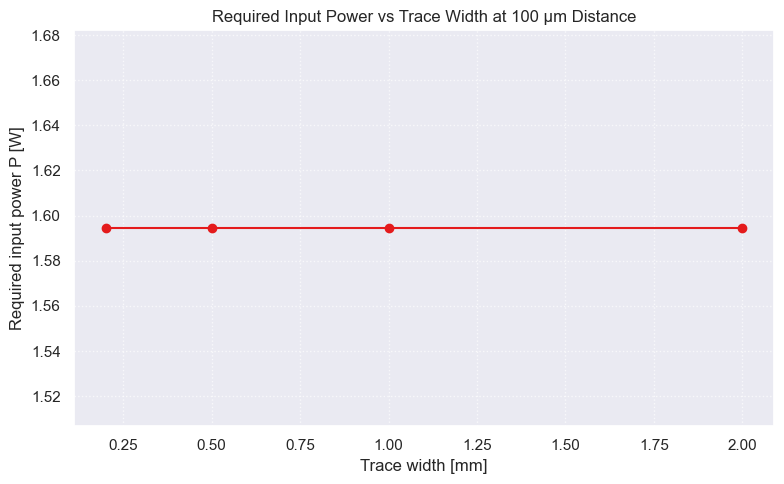

Width 2.00 mm: R_RF(RT)=0.1284 ohm, R_RF(cryo)=0.0044 ohm
Width 1.00 mm: R_RF(RT)=0.2568 ohm, R_RF(cryo)=0.0088 ohm
Width 0.50 mm: R_RF(RT)=0.5135 ohm, R_RF(cryo)=0.0176 ohm
Width 0.20 mm: R_RF(RT)=1.2838 ohm, R_RF(cryo)=0.0440 ohm


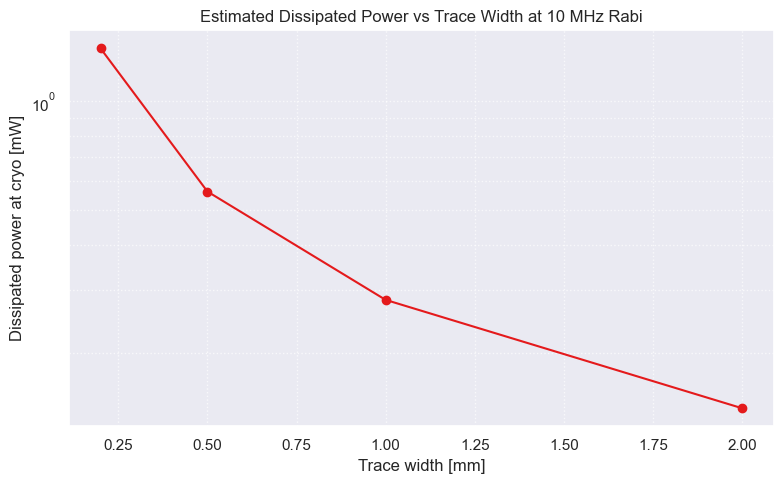

Width 2.00 mm: dissipated power = 140.41 µW
Width 1.00 mm: dissipated power = 280.82 µW
Width 0.50 mm: dissipated power = 561.64 µW
Width 0.20 mm: dissipated power = 1404.11 µW


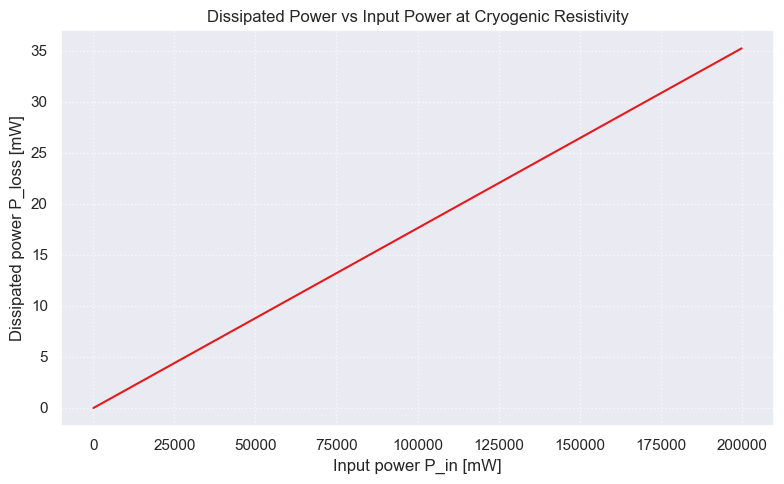

Example RF resistance at 1 mm width: 0.008807 ohm


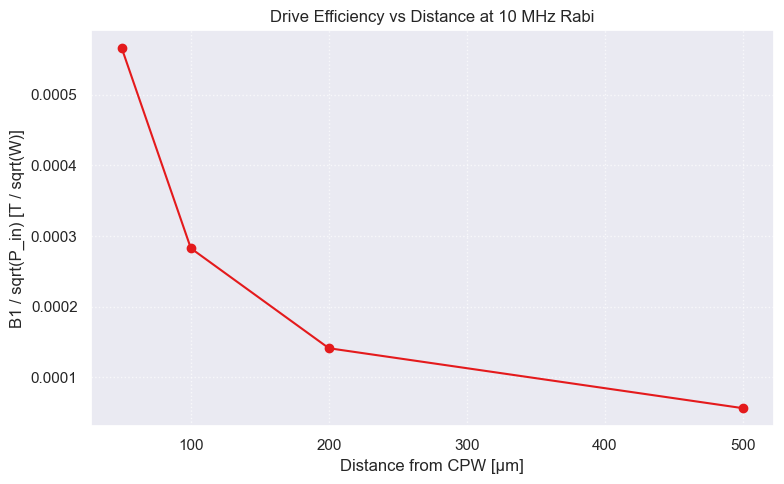

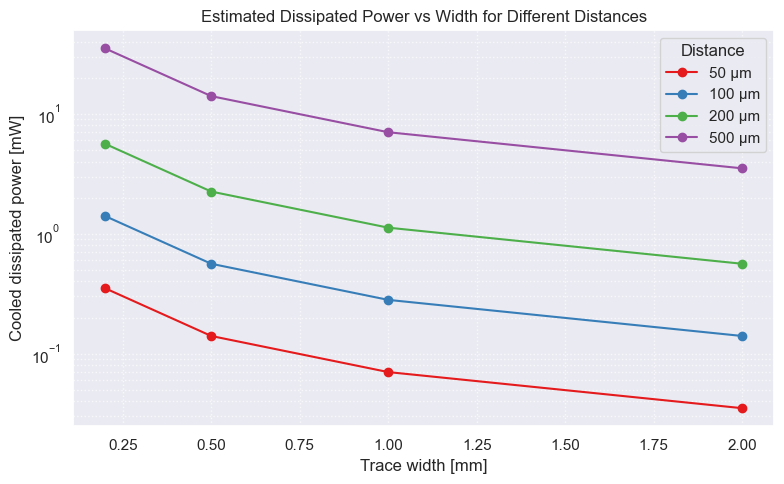

Key numeric summary for 5 MHz Rabi at 100 µm:
  Required current: 0.179 A
  Required input power: 1594.39 mW
  Cryo RF resistance (1 mm width): 0.008807 ohm
  Dissipated power at cryo: 280.82 µW

Feasibility note: typical mK refrigerators support ~10-100 µW of heat load. The trace dissipation here is in the sub-µW to µW range for a 1 mm cryo trace, but the delivered microwave power of several mW still needs careful management through the cold line.


In [73]:
# Section 4: Required power vs trace width
representative_r = 100e-6  # representative distance [m]
I_fixed_r = current_for_rabi(fixed_rabi, representative_r)
P_fixed_r = power_from_current(I_fixed_r)

plt.figure(figsize=(8, 5))
plt.plot(widths * 1e3, [P_fixed_r] * len(widths), marker='o')
plt.xlabel('Trace width [mm]')
plt.ylabel('Required input power P [W]')
plt.title('Required Input Power vs Trace Width at 100 µm Distance')
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

omega_nv = 2 * np.pi * f_nv
R_rf_RT = rf_resistance(rho_RT, widths, omega_nv)
R_rf_cryo = rf_resistance(rho_cryo, widths, omega_nv)

for w, rrt, rcr in zip(widths, R_rf_RT, R_rf_cryo):
    print(f'Width {w*1e3:.2f} mm: R_RF(RT)={rrt:.4f} ohm, R_RF(cryo)={rcr:.4f} ohm')

# Section 5: RF resistance and dissipated power at cryogenic temperatures
R_rf_cryo_widths = rf_resistance(rho_cryo, widths, omega_nv)
P_loss_cryo = dissipated_power(I_fixed_r, R_rf_cryo_widths)

plt.figure(figsize=(8, 5))
plt.plot(widths * 1e3, P_loss_cryo * 1e3, marker='o')
plt.xlabel('Trace width [mm]')
plt.ylabel('Dissipated power at cryo [mW]')
plt.title(f'Estimated Dissipated Power vs Trace Width at {fixed_rabi * 1e-6:.0f} MHz Rabi')
plt.yscale('log')
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

for w, pl in zip(widths, P_loss_cryo):
    print(f'Width {w*1e3:.2f} mm: dissipated power = {pl*1e6:.2f} µW')

# Section 6: Dissipated power vs input power at cryo
I_range = np.linspace(0.01, 2.0, 200)  # current sweep [A]
P_in = power_from_current(I_range)
R_rf_example = rf_resistance(rho_cryo, 1e-3, omega_nv)
P_loss_range = dissipated_power(I_range, R_rf_example)

plt.figure(figsize=(8, 5))
plt.plot(P_in * 1e3, P_loss_range * 1e3)
plt.xlabel('Input power P_in [mW]')
plt.ylabel('Dissipated power P_loss [mW]')
plt.title('Dissipated Power vs Input Power at Cryogenic Resistivity')
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

print(f'Example RF resistance at 1 mm width: {R_rf_example:.6f} ohm')

# Section 7: Distance and width scaling for heating and efficiency
efficiency = []
for r in distances:
    I_req = current_for_rabi(fixed_rabi, r)
    efficiency.append(b1_from_current(I_req, r) / np.sqrt(power_from_current(I_req)))
efficiency = np.array(efficiency)

plt.figure(figsize=(8, 5))
plt.plot(distances * 1e6, efficiency, marker='o')
plt.xlabel('Distance from CPW [µm]')
plt.ylabel('B1 / sqrt(P_in) [T / sqrt(W)]')
plt.title(f'Drive Efficiency vs Distance at {fixed_rabi * 1e-6:.0f} MHz Rabi')
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

P_loss_matrix = np.array([
    dissipated_power(current_for_rabi(fixed_rabi, r), R_rf_cryo_widths)
    for r in distances
])

plt.figure(figsize=(8, 5))
for i, r in enumerate(distances):
    plt.plot(widths * 1e3, P_loss_matrix[i] * 1e3, marker='o', label=f'{r*1e6:.0f} µm')
plt.xlabel('Trace width [mm]')
plt.ylabel('Cooled dissipated power [mW]')
plt.title('Estimated Dissipated Power vs Width for Different Distances')
plt.yscale('log')
plt.legend(title='Distance')
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

# Section 8: Numeric summary and feasibility commentary
target_r = 100e-6
I_target = current_for_rabi(fixed_rabi, target_r)
P_target = power_from_current(I_target)
R_rf_target = rf_resistance(rho_cryo, 1e-3, omega_nv)
P_loss_target = dissipated_power(I_target, R_rf_target)

print('Key numeric summary for 5 MHz Rabi at 100 µm:')
print(f'  Required current: {I_target:.3f} A')
print(f'  Required input power: {P_target*1e3:.2f} mW')
print(f'  Cryo RF resistance (1 mm width): {R_rf_target:.6f} ohm')
print(f'  Dissipated power at cryo: {P_loss_target*1e6:.2f} µW')
print('')
print('Feasibility note: typical mK refrigerators support ~10-100 µW of heat load. The trace dissipation here is in the sub-µW to µW range for a 1 mm cryo trace, but the delivered microwave power of several mW still needs careful management through the cold line.')

# PHYSICALLY ACCURATE FIELD MODEL AND DESIGN OPTIMIZATION

This section replaces the simple thin-wire approximation with a finite-width strip model for more accurate CPW field calculations. It includes design optimization sweeps and feasibility constraints.

## SECTION 1 – IMPROVED MAGNETIC FIELD MODEL

Replace the simple thin-wire approximation with a finite-width strip model derived from Biot-Savart law.

In [ ]:
# Finite-width strip approximation for B1
def b1_strip(I, z, W):
    """Magnetic field amplitude above the center of a finite-width strip conductor."""
    # I is peak current, z is distance, W is width
    term1 = W/2 + np.sqrt((W/2)**2 + z**2)
    return (mu0 * I / (2 * np.pi * W)) * np.log(term1 / z)

# Compare thin-wire vs strip model
strip_widths = np.array([0.2e-3, 0.5e-3, 1e-3, 2e-3])  # 0.2 mm, 0.5 mm, 1 mm, 2 mm
compare_distances = np.array([50e-6, 100e-6, 200e-6])  # 50, 100, 200 um

plt.figure(figsize=(10, 6))
for i, z in enumerate(compare_distances):
    for j, W in enumerate(strip_widths):
        B1_strip = b1_strip(I_values, z, W) * 1e3
        plt.plot(I_values, B1_strip, label=f'Strip W={W*1e3:.1f} mm, z={z*1e6:.0f} µm', linestyle='--')
    
    B1_wire = b1_from_current(I_values, z) * 1e3
    plt.plot(I_values, B1_wire, label=f'Wire z={z*1e6:.0f} µm', color=f'C{i}', linewidth=2)

plt.xlabel('Current I [A]')
plt.ylabel('B1 amplitude [mT]')
plt.title('B1 vs Current: Thin-Wire vs Finite-Width Strip Models')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

## SECTION 2 – REQUIRED CURRENT AND POWER FOR NV DRIVING

Target Rabi frequency: 10 MHz. Compute required B1 and current using the strip model.

In [ ]:
# Target Rabi and required B1
Omega_target = 10e6  # 10 MHz
B1_required = Omega_target / gamma_e  # Required B1 amplitude [T]

# Current required for strip model
def current_for_rabi_strip(Omega, z, W):
    """Current required for Rabi Omega at distance z, width W using strip model."""
    B1_req = Omega / gamma_e
    # Solve for I: B1_strip(I, z, W) = B1_req
    # Since B1 ∝ I, I = B1_req / (b1_strip(1, z, W))
    return B1_req / b1_strip(1, z, W)

# Plot required current vs distance for different widths
dist_sweep = np.linspace(50e-6, 500e-6, 100)
plt.figure(figsize=(8, 5))
for W in strip_widths:
    I_req_strip = [current_for_rabi_strip(Omega_target, z, W) for z in dist_sweep]
    plt.plot(dist_sweep * 1e6, I_req_strip, label=f'W = {W*1e3:.1f} mm')

plt.xlabel('Distance z [µm]')
plt.ylabel('Required current I [A]')
plt.title(f'Required Current vs Distance for {Omega_target*1e-6:.0f} MHz Rabi (Strip Model)')
plt.legend()
plt.yscale('log')
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

# Plot required current vs width for fixed distance
fixed_z = 200e-6  # 200 um
width_sweep = np.linspace(0.1e-3, 2e-3, 100)
I_req_vs_width = [current_for_rabi_strip(Omega_target, fixed_z, W) for W in width_sweep]
plt.figure(figsize=(8, 5))
plt.plot(width_sweep * 1e3, I_req_vs_width)
plt.xlabel('Trace width W [mm]')
plt.ylabel('Required current I [A]')
plt.title(f'Required Current vs Width at z = {fixed_z*1e6:.0f} µm for {Omega_target*1e-6:.0f} MHz Rabi')
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

# Required power
P_req_vs_dist = [power_from_current(current_for_rabi_strip(Omega_target, z, 2e-3)) for z in dist_sweep]
P_req_vs_width = [power_from_current(current_for_rabi_strip(Omega_target, fixed_z, W)) for W in width_sweep]

plt.figure(figsize=(8, 5))
plt.plot(dist_sweep * 1e6, np.array(P_req_vs_dist) * 1e3)
plt.xlabel('Distance z [µm]')
plt.ylabel('Required power P [mW]')
plt.title(f'Required Power vs Distance (W=2 mm, {Omega_target*1e-6:.0f} MHz Rabi)')
plt.yscale('log')
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(width_sweep * 1e3, np.array(P_req_vs_width) * 1e3)
plt.xlabel('Trace width W [mm]')
plt.ylabel('Required power P [mW]')
plt.title(f'Required Power vs Width (z={fixed_z*1e6:.0f} µm, {Omega_target*1e-6:.0f} MHz Rabi)')
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

# Highlight current design: W=2 mm, z=200 um
I_current_design = current_for_rabi_strip(Omega_target, 200e-6, 2e-3)
P_current_design = power_from_current(I_current_design)
print(f'Current design (W=2 mm, z=200 µm): I = {I_current_design:.3f} A, P = {P_current_design*1e3:.2f} mW')

## SECTION 3 – RF RESISTANCE AND HEATING

Compute RF resistance and dissipated power at cryogenic temperatures.

In [ ]:
# RF resistance at 2.87 GHz
R_rf_strip_RT = rf_resistance(rho_RT, strip_widths, omega_nv)
R_rf_strip_cryo = rf_resistance(rho_cryo, strip_widths, omega_nv)

# Dissipated power for current design
I_design = current_for_rabi_strip(Omega_target, 200e-6, 2e-3)
P_loss_strip_cryo = dissipated_power(I_design, R_rf_strip_cryo)

plt.figure(figsize=(8, 5))
plt.plot(strip_widths * 1e3, P_loss_strip_cryo * 1e6, marker='o')
plt.axhline(100, color='red', linestyle='--', label='100 µW limit')
plt.xlabel('Trace width W [mm]')
plt.ylabel('Dissipated power [µW]')
plt.title(f'Dissipated Power vs Width at Cryo (z=200 µm, {Omega_target*1e-6:.0f} MHz Rabi)')
plt.legend()
plt.yscale('log')
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

# Dissipated power vs distance for W=2 mm
dist_sweep_coarse = np.linspace(50e-6, 500e-6, 50)
P_loss_vs_dist = [dissipated_power(current_for_rabi_strip(Omega_target, z, 2e-3), rf_resistance(rho_cryo, 2e-3, omega_nv)) for z in dist_sweep_coarse]

plt.figure(figsize=(8, 5))
plt.plot(dist_sweep_coarse * 1e6, np.array(P_loss_vs_dist) * 1e6, marker='o')
plt.axhline(100, color='red', linestyle='--', label='100 µW limit')
plt.xlabel('Distance z [µm]')
plt.ylabel('Dissipated power [µW]')
plt.title(f'Dissipated Power vs Distance at Cryo (W=2 mm, {Omega_target*1e-6:.0f} MHz Rabi)')
plt.legend()
plt.yscale('log')
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

## SECTION 4 – DESIGN OPTIMIZATION SWEEP

Parameter sweep over width (0.1–2 mm) and distance (20–500 µm) for efficiency metrics.

In [ ]:
# Parameter sweep
width_grid = np.linspace(0.1e-3, 2e-3, 20)
dist_grid = np.linspace(20e-6, 500e-6, 20)
W_mesh, Z_mesh = np.meshgrid(width_grid, dist_grid)

# Compute metrics
P_req_mesh = np.zeros_like(W_mesh)
P_loss_mesh = np.zeros_like(W_mesh)
efficiency_mesh = np.zeros_like(W_mesh)

for i, z in enumerate(dist_grid):
    for j, w in enumerate(width_grid):
        I_req = current_for_rabi_strip(Omega_target, z, w)
        P_req = power_from_current(I_req)
        R_rf = rf_resistance(rho_cryo, w, omega_nv)
        P_loss = dissipated_power(I_req, R_rf)
        B1 = b1_strip(I_req, z, w)
        
        P_req_mesh[i, j] = P_req
        P_loss_mesh[i, j] = P_loss
        efficiency_mesh[i, j] = B1 / np.sqrt(P_req)

# Heatmaps
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Required RF power
c1 = axes[0].contourf(W_mesh * 1e3, Z_mesh * 1e6, P_req_mesh * 1e3, levels=np.logspace(-1, 2, 20), cmap='viridis', norm=LogNorm())
axes[0].set_xlabel('Width [mm]')
axes[0].set_ylabel('Distance [µm]')
axes[0].set_title('Required RF Power [mW] (log scale)')
fig.colorbar(c1, ax=axes[0])

# Dissipated power
c2 = axes[1].contourf(W_mesh * 1e3, Z_mesh * 1e6, P_loss_mesh * 1e6, levels=np.logspace(-1, 3, 20), cmap='plasma', norm=LogNorm())
axes[1].set_xlabel('Width [mm]')
axes[1].set_ylabel('Distance [µm]')
axes[1].set_title('Dissipated Power [µW] (log scale)')
fig.colorbar(c2, ax=axes[1])

# Efficiency
c3 = axes[2].contourf(W_mesh * 1e3, Z_mesh * 1e6, efficiency_mesh, levels=20, cmap='coolwarm')
axes[2].set_xlabel('Width [mm]')
axes[2].set_ylabel('Distance [µm]')
axes[2].set_title('Efficiency B1 / sqrt(P) [T/W^{0.5}]')
fig.colorbar(c3, ax=axes[2])

plt.tight_layout()
plt.show()